In [2]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
flopp_norm = pd.read_csv('flopp_normal.csv')
del flopp_norm['Unnamed: 0']
flopp_norm.columns = list(np.float64(flopp_norm.columns[:-1])) + list(flopp_norm.columns[-1:])
flopp_norm

,987.4166,989.3451,991.2737,993.2023,995.1307,997.0593,998.9879,1000.916,1002.845,1004.774,...,2958.393,2960.321,2962.25,2964.178,2966.107,2968.035,2969.964,2971.893,2973.821,polymer
0,1.064749,1.055943,1.041991,1.030707,1.029863,1.036533,1.039255,1.038075,1.028994,1.048059,...,-1.143742,-1.262707,-1.361013,-1.406754,-1.446765,-1.469616,-1.521524,-1.581927,-1.619016,Acrylonitrile Butadiene Styrene
1,0.990692,0.983819,0.979710,0.977673,0.984577,0.996374,0.991542,0.972306,0.977345,1.016625,...,-0.640407,-0.760776,-0.880944,-0.971311,-1.041472,-1.097428,-1.181162,-1.271503,-1.339314,Acrylonitrile Butadiene Styrene
2,0.743762,0.662994,0.626800,0.630767,0.669683,0.723454,0.759620,0.740156,0.685080,0.654562,...,0.374245,0.269232,0.153409,0.051003,-0.039844,-0.138918,-0.283444,-0.431125,-0.545120,Acrylonitrile Butadiene Styrene
3,1.090603,0.967431,0.919953,0.901465,0.922234,0.972344,0.994307,0.949643,0.852486,0.771909,...,0.316006,0.147910,-0.027503,-0.157863,-0.265031,-0.366640,-0.494878,-0.605140,-0.682944,Acrylonitrile Butadiene Styrene
4,0.560128,0.511260,0.478157,0.447734,0.420904,0.397945,0.383034,0.364720,0.343706,0.360659,...,0.650102,0.569649,0.462172,0.381327,0.302254,0.214470,0.067647,-0.096017,-0.231292,Acrylonitrile Butadiene Styrene
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,1.042861,0.905142,0.778140,0.673171,0.590348,0.523801,0.469691,0.422008,0.371084,0.330100,...,-0.326638,-0.328530,-0.342257,-0.351409,-0.344914,-0.330440,-0.333551,-0.348560,-0.366255,Polyvinyl Chloride
377,0.899680,0.869254,0.850311,0.844992,0.845802,0.843710,0.836004,0.831513,0.826411,0.830894,...,0.362460,0.419141,0.444180,0.432955,0.390847,0.325844,0.240190,0.135104,0.023711,Polyvinyl Chloride
378,1.642534,1.569093,1.504311,1.466815,1.446367,1.432468,1.414033,1.412929,1.440695,1.478013,...,-0.403775,-0.399453,-0.406964,-0.421348,-0.419719,-0.417596,-0.421470,-0.433325,-0.450099,Polyvinyl Chloride
379,1.193265,1.091474,1.013518,0.948943,0.893909,0.863824,0.838624,0.812180,0.792994,0.788443,...,-0.546566,-0.535380,-0.536203,-0.542429,-0.539133,-0.531315,-0.542059,-0.567365,-0.594541,Polyvinyl Chloride


In [4]:
reb_ir_normal = pd.read_csv('reb_ir_normal.csv')
del reb_ir_normal['Unnamed: 0']
reb_ir_normal.columns = list(np.float64(reb_ir_normal.columns[:-1])) + list(reb_ir_normal.columns[-1:])
reb_ir_normal

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2953.140869140625,2955.06982421875,2956.998779296875,2958.927734375,2960.856689453125,2962.785888671875,2964.71484375,2966.643798828125,2968.57275390625,polymer
0,-0.392640,-0.454601,-0.464990,-0.329573,-0.088034,0.176476,0.166450,0.163437,0.204965,0.149096,...,-0.698976,-0.881505,-0.868517,-0.694837,-0.705542,-0.745512,-0.532313,-0.342508,-0.245753,sucrose
1,-0.732914,-0.395826,-0.282197,-0.165558,-0.157994,-0.162367,0.006924,0.155119,0.165545,0.145340,...,-0.169306,-0.232536,-0.426117,-0.659030,-0.854222,-0.935647,-0.693358,-0.078311,0.276210,sucrose
2,-0.495824,-0.419892,-0.323674,-0.230586,-0.064443,-0.042621,-0.044761,0.055806,0.112600,0.030577,...,-0.039571,-0.469880,-0.396053,-0.229724,-0.124085,-0.127805,-0.523796,-0.774176,-0.849349,sucrose
3,0.273176,-0.167022,-0.900395,-0.682565,-0.575114,-0.632725,-0.720779,-0.926019,-0.710402,-0.093024,...,-2.231216,-0.808675,-1.822303,-2.789836,-1.542131,-1.755101,-1.934418,-2.469803,-3.990350,sucrose
4,-0.555854,0.464408,-0.346423,0.469787,0.572545,0.113482,-0.041214,-0.139890,0.020944,0.179639,...,-4.455813,-0.467089,0.524960,-1.949237,-3.870582,-5.888054,-5.303791,-2.051834,-1.711778,sucrose
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,-1.297317,-0.947815,0.530858,1.815698,2.515687,1.382142,-0.030091,-0.533222,0.425743,0.832528,...,1.023941,-2.026167,-1.517234,0.776622,2.287639,2.539271,1.581773,-1.865727,-3.876430,PP
521,-0.662795,-0.576513,-0.582615,-0.592893,-0.557169,-0.535071,-0.463637,-0.384585,-0.350118,-0.322597,...,2.131391,2.017177,1.988845,1.844224,1.766090,1.529831,0.961710,0.459522,-0.321061,PP
522,-0.419275,-0.508081,-0.501921,-0.495025,-0.488449,-0.517389,-0.475998,-0.360246,-0.374320,-0.421923,...,3.512320,3.077941,3.107308,3.359467,3.539733,3.187655,2.137266,1.394103,1.618054,PP
523,-0.953599,-1.061768,-0.813303,-0.684921,-0.529591,-0.589892,-0.451891,-0.422223,-0.372896,-0.205361,...,1.871700,1.453724,1.584908,2.663901,2.568633,1.925870,0.675188,-2.077789,-3.346421,PP


In [5]:
spectra_data_ir_res = pd.read_csv('spectra_with_matches.csv')
del spectra_data_ir_res['Unnamed: 0']
spectra_data_ir_res.columns = list(np.float64(spectra_data_ir_res.columns[:-8])) + list(spectra_data_ir_res.columns[-8:])
spectra_data_ir_res

,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2966.643798828125,2968.57275390625,map_x,map_y,id,background,polymer_flopp,hqi_flopp,polymer_reb_ir,hqi_reb_ir
0,1.734127,2.419397,-0.399766,-0.750546,0.913183,1.100276,-0.134475,-0.985368,-0.951970,0.834969,...,-2.201744,1.236354,19395.199219,2398.699951,FHS_passive_July2024_D6_20240813_1,background,Polyethylene,0.132510,PP,0.243776
1,0.091801,-1.828973,0.008286,0.387269,-0.509035,0.612197,0.154604,-1.152029,-0.440574,-0.526350,...,3.464395,2.477008,19384.699219,2399.100098,FHS_passive_July2024_D6_20240813_2,background,Polyethylene Vinyl Acetate,0.177957,NaNO3,0.282903
2,-0.075321,-0.260037,0.363896,-0.511174,-1.167597,-0.814324,-0.546396,-0.199241,-0.720920,-0.422421,...,-6.916821,-7.919211,19409.099609,2405.399902,FHS_passive_July2024_D6_20240813_3,background,Polyethylene,0.226736,PSL,0.564189
3,-0.651419,-0.267902,-0.174596,-0.647592,-0.307889,-0.670411,-0.414515,-0.084047,-0.744710,-1.285505,...,0.086870,3.337598,19372.000000,2407.199951,FHS_passive_July2024_D6_20240813_4,background,Polypropylene,0.212510,NaNO3,0.371484
4,1.737391,2.278559,1.263099,-0.660179,-0.606585,0.049145,-0.122640,0.073713,0.342571,-0.002320,...,5.291844,4.058921,19411.849609,2410.850098,FHS_passive_July2024_D6_20240813_5,background,Polycarbonate,0.109361,PP,0.332466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4363,0.956464,1.418004,2.014006,1.909727,2.217237,2.613354,2.636785,2.509610,2.364499,2.146140,...,-1.045898,0.010922,7783.100098,-485.600006,IAO_passive_June2024_G7_20240801_39,no_background,Rubber,0.943897,sucrose,0.772961
4364,-0.183061,-0.095919,-0.119556,-0.174708,-0.151427,-0.145177,-0.146811,-0.114293,-0.098024,-0.112260,...,-0.746549,-0.828798,7778.299805,-487.200012,IAO_passive_June2024_G7_20240801_40,no_background,Polystyrene,0.696300,NaNO3,0.978374
4365,1.963018,1.809682,1.968297,1.946081,1.803461,1.980056,2.149049,2.324492,2.393598,2.233794,...,-1.230737,-0.983616,7740.350098,-478.950012,IAO_passive_June2024_G7_20240801_41,no_background,Rubber,0.935549,sucrose,0.767207
4366,1.757011,2.201591,2.704748,2.676028,2.120502,1.967140,1.924711,1.644775,1.611892,1.948868,...,-0.961392,-0.633345,7828.049805,-470.100006,IAO_passive_June2024_G7_20240801_42,no_background,Rubber,0.921852,sucrose,0.789811


In [6]:
matches_list_flopp = np.unique(spectra_data_ir_res['polymer_flopp'])
matches_list_reb = np.unique(spectra_data_ir_res['polymer_reb_ir'])

In [17]:
(spectra_data_ir_res.query('hqi_flopp >.7').shape[0] / spectra_data_ir_res.shape[0],
spectra_data_ir_res.query('hqi_reb_ir >.7').shape[0] / spectra_data_ir_res.shape[0])

(0.4539835164835165, 0.4649725274725275)

Acrylic 1


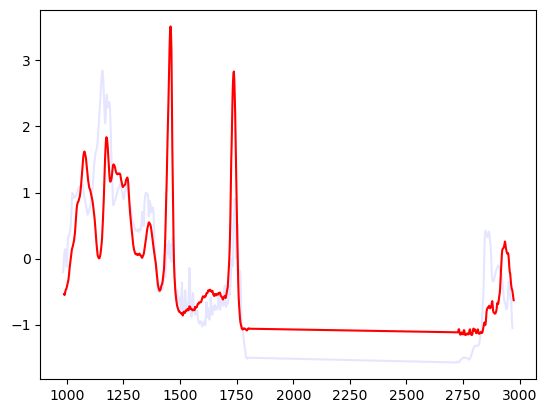

Acrylonitrile Butadiene Styrene 9


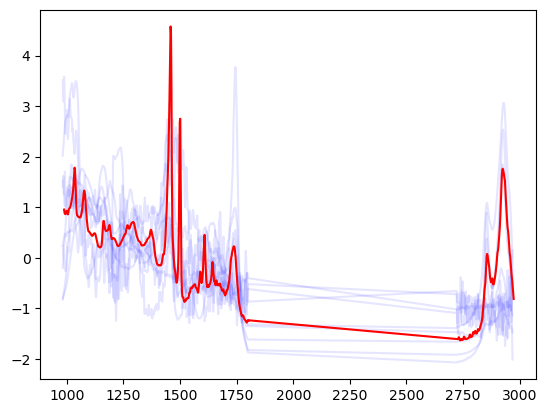

Cellulose Acetate 2


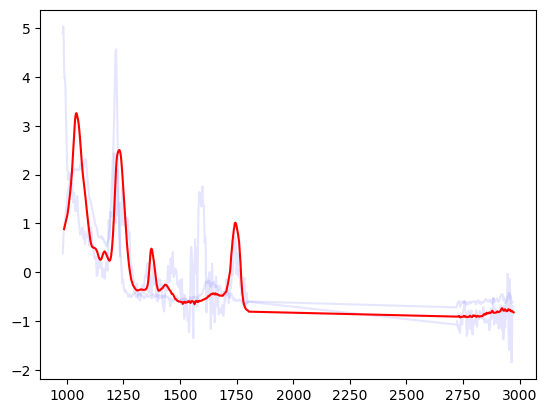

Cotton 131


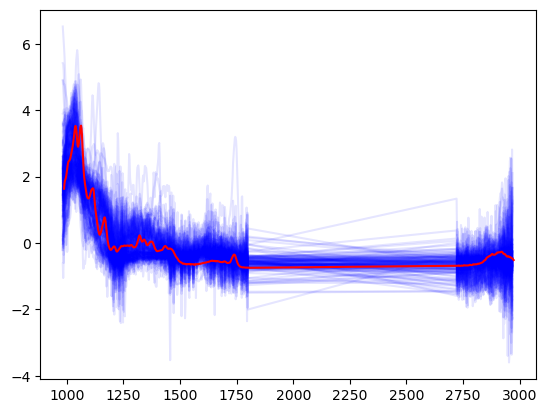

Ethylene Acrylic Acid 1


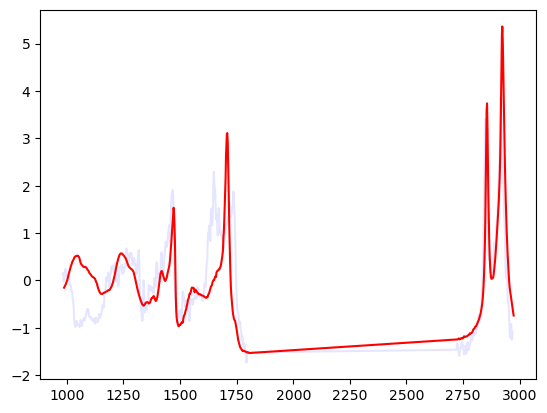

Polyamide 22


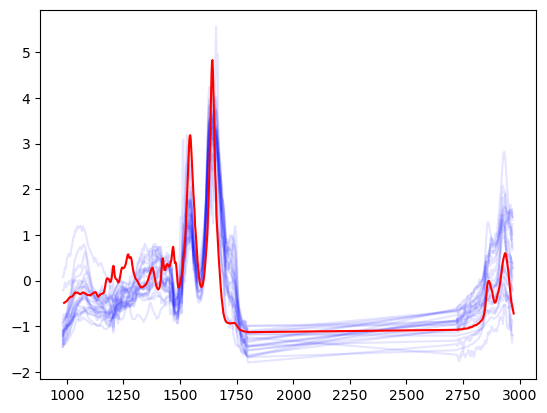

Polycarbonate 2


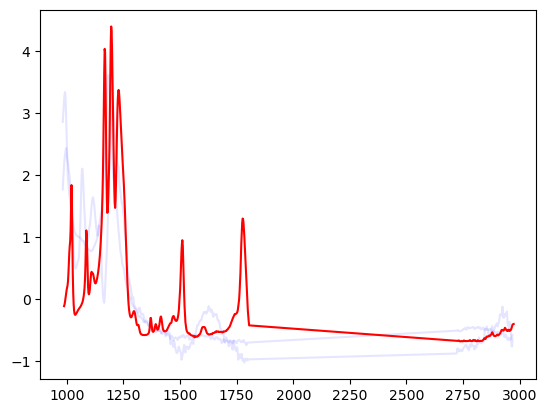

Polyethylene 61


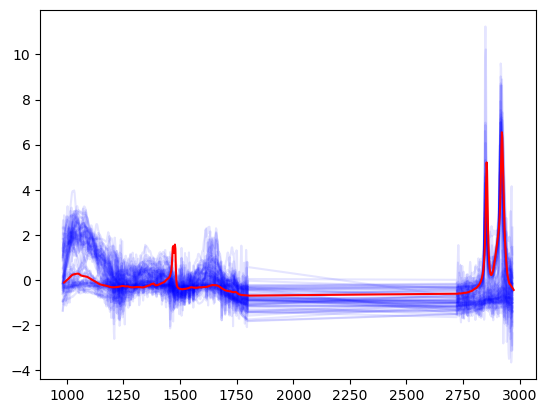

Polyethylene Adipate 1


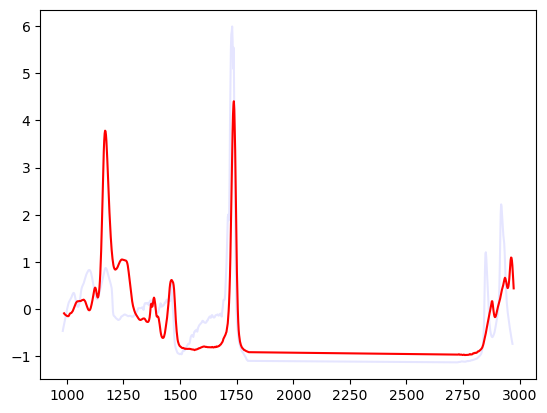

Polyethylene Terephthalate 1


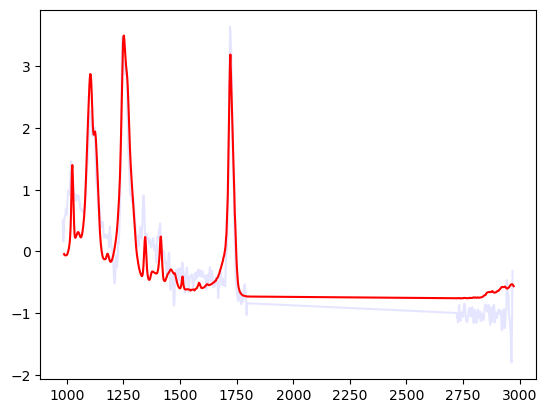

Polyethylene Vinyl Acetate 2


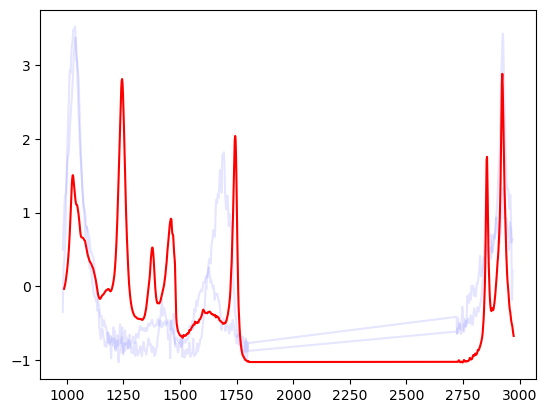

Polylactic acid 0


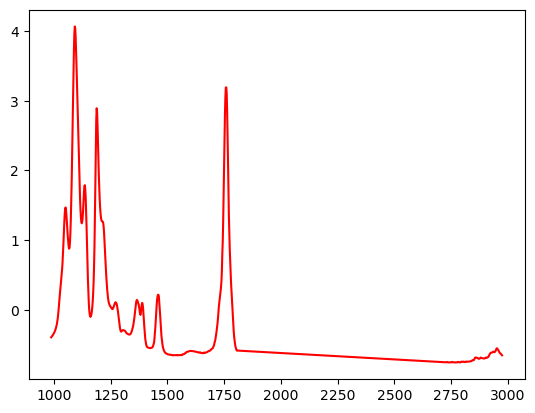

Polymethyl Methacrylate 3


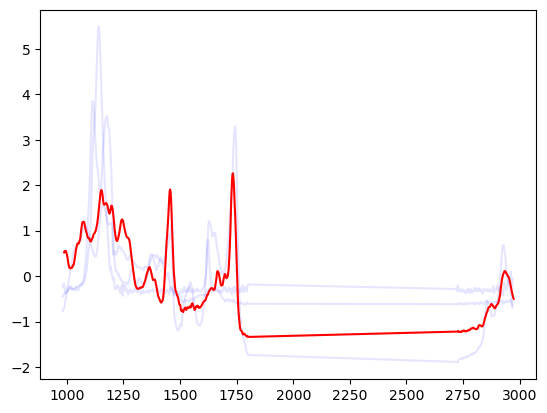

Polypropylene 99


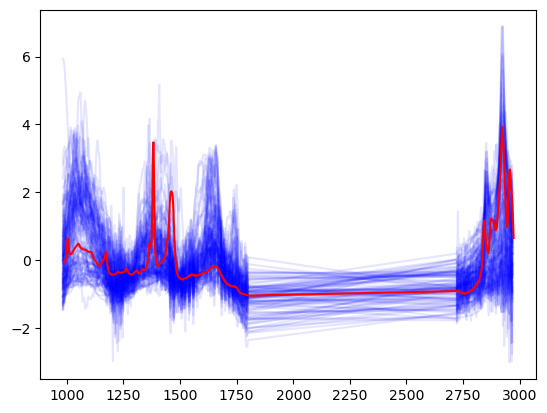

Polystyrene 376


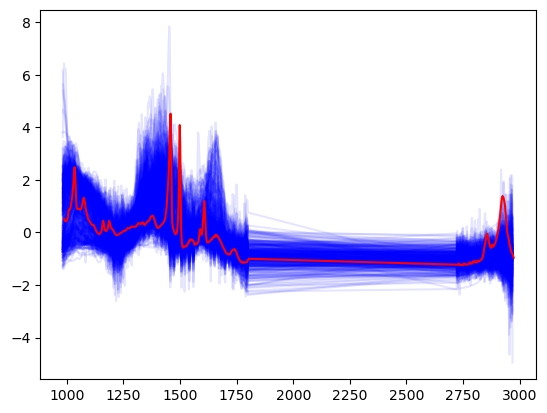

Polyurethane 25


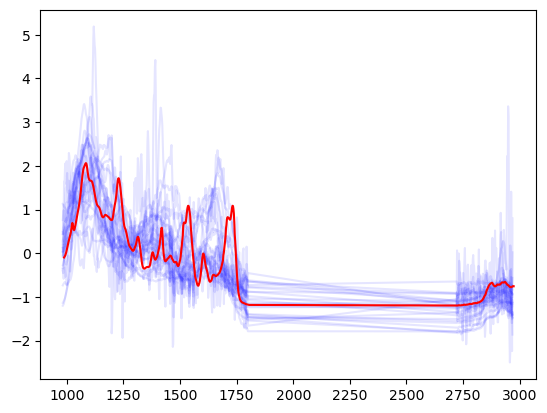

Polyvinyl Chloride 10


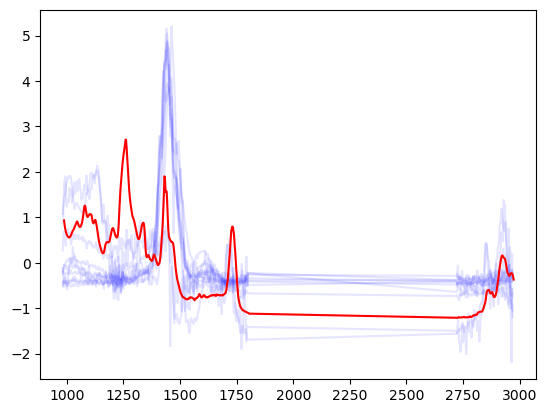

Rubber 1237


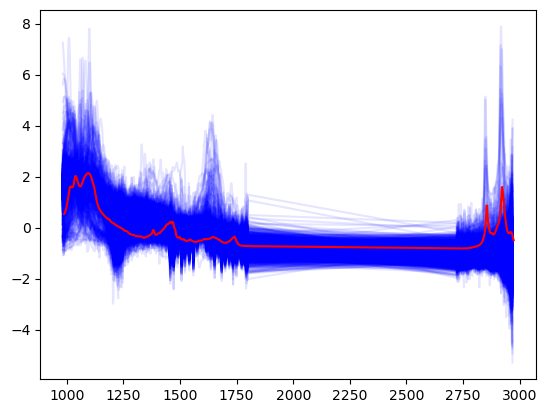

Silicone Rubber 0


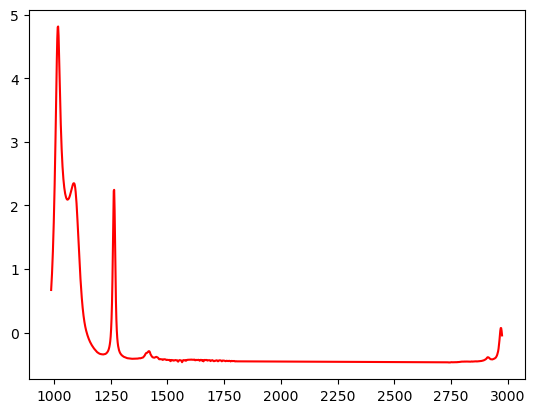

In [31]:
for i in range(matches_list_flopp.shape[0]):
    poly = matches_list_flopp[i]
    df_poly = spectra_data_ir_res.query('polymer_flopp == @poly and hqi_flopp > 0.70')
    print(poly, df_poly.shape[0])
    _ = plt.plot(df_poly.iloc[:,:-8].T, c='b', alpha=.1, label='passive_data')
    _ = plt.plot(flopp_norm.query('polymer == @poly').iloc[:,:-1].mean(0), c='r', label='flopp')
    _ = plt.show()

NH2SO4 3


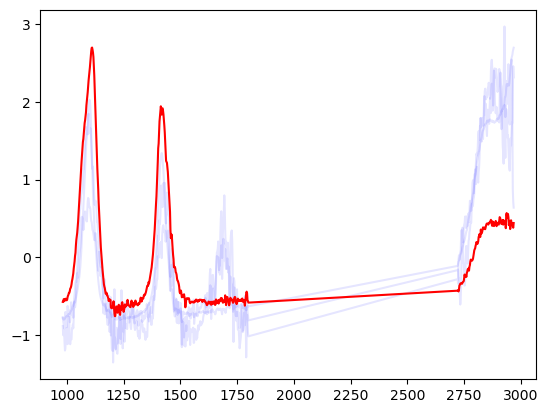

NaNO3 24


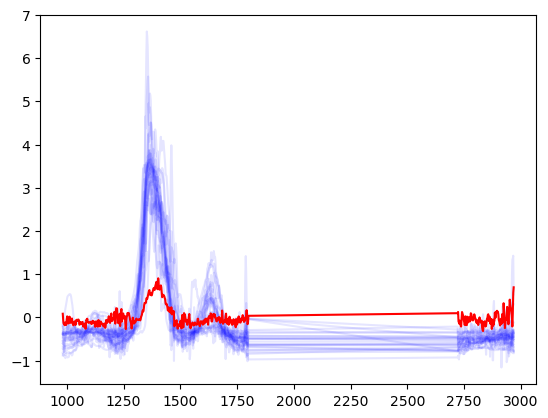

PE 13


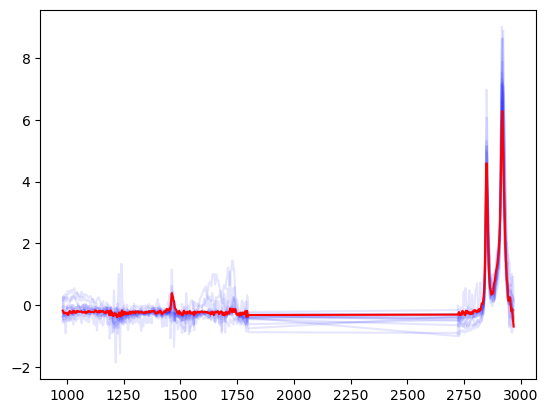

PP 11


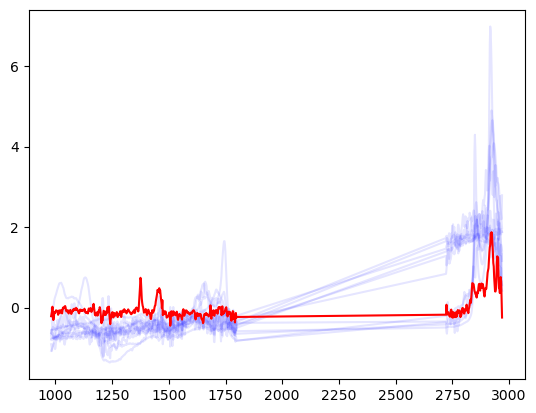

PSL 15


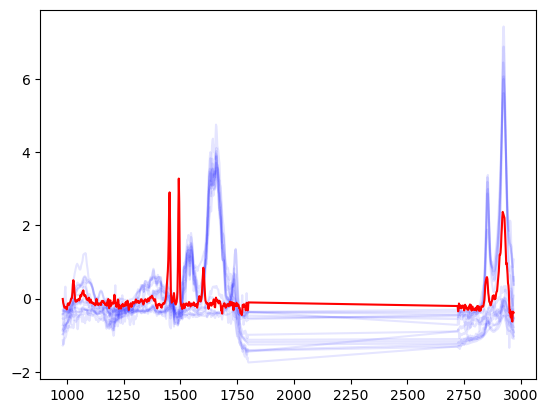

sucrose 124


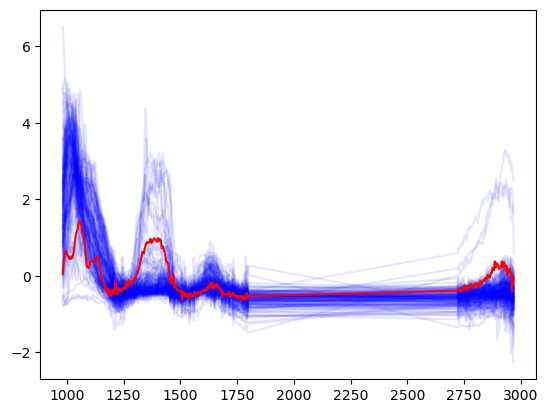

In [39]:
for i in range(matches_list_reb.shape[0]):
    poly = matches_list_reb[i]
    df_poly = spectra_data_ir_res.query('polymer_reb_ir == @poly and hqi_reb_ir > 0.90')
    print(poly, df_poly.shape[0])
    _ = plt.plot(df_poly.iloc[:,:-8].T, c='b', alpha=.1, label='passive_data')
    _ = plt.plot(reb_ir_normal.query('polymer == @poly').iloc[:,:-1].mean(0), c='r', label='flopp')
    _ = plt.show()